# Project Notebook

<a target="_blank" href="https://colab.research.google.com/github/drchadvidden/courseMaterials/blob/main/DifferentialEquations/Projects/Project_Template.ipynb">
<img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/>
</a>

Instruction: Modify the below notebook structure to complete the project. See Canvas for full details.

# Part 1 — Reproduce and Explain

Markdown explanation of ideas.

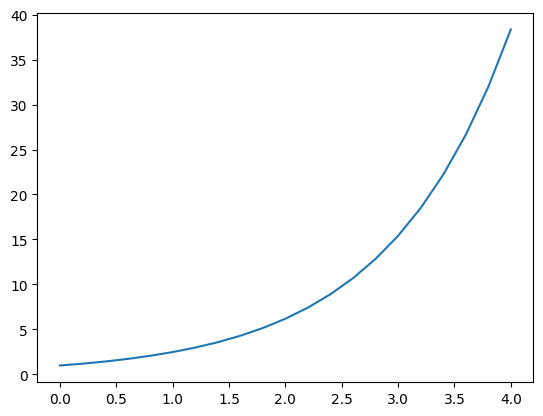

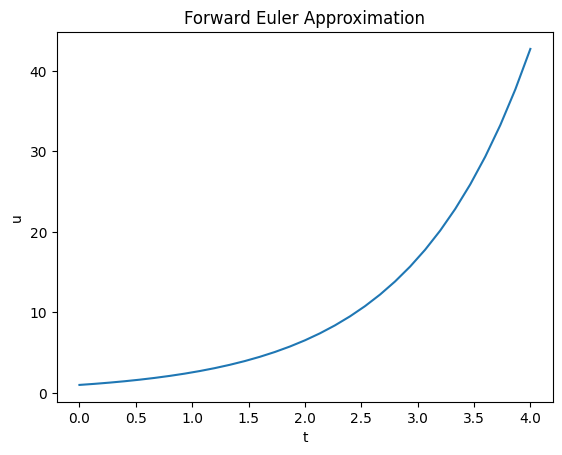

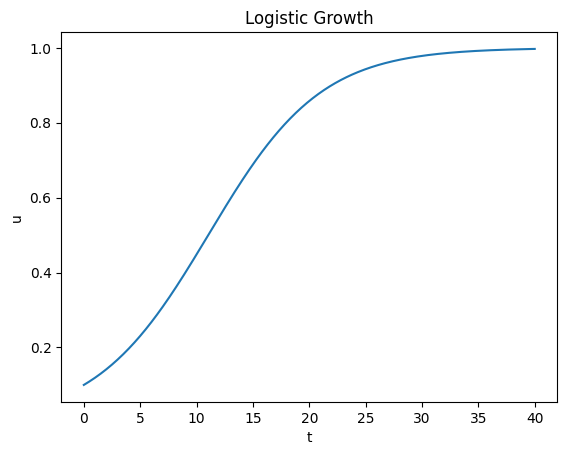

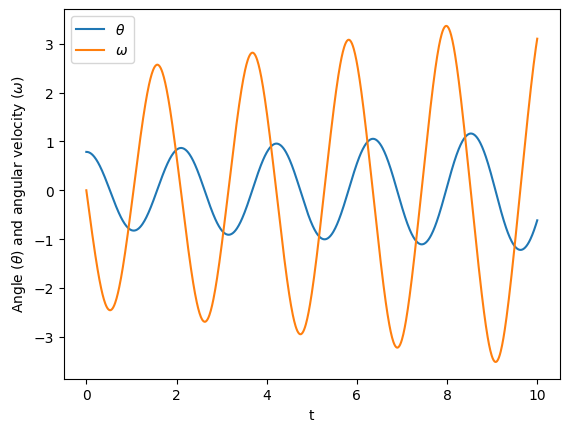

Time step (dt)   Error (e)      e/dt
0.1000000        2.6361347      26.3613
0.0500000        1.4063510      28.1270
0.0250000        0.7273871      29.0955
0.0125000        0.3700434      29.6035
0.0062500        0.1866483      29.8637
0.0031250        0.0937359      29.9955
0.0015625        0.0469715      30.0618
0.0007813        0.0235117      30.0950
0.0003906        0.0117624      30.1116
0.0001953        0.0058828      30.1200
[3, 1, 4, 1, 5]


In [28]:
# python code from text with possible modifications

# so basically we are using the idea of Euler's method to solve ODEs
# we need it to work for IVPs as well. (a differential equation with a given
# starting point)
# We use the idea of the Forward Euler method
# if we have an ODE:
# u'(t_n) = f(t_n,u(t_n)),
# we can approximate u'(t_n) by a forward finite distance
# u'(t_n) = (u(t_n+1) - u(t_n)) / (deltat)
# through some SOLVING we can get u(t_n+1) = u(t_n) + deltat * f(t_n , u(t_n))
# in human terms this means your next estimated point = your current value +
# a small change based on the current slope.
# now we need to do THIS with python:
# 1. Create arrays t and u of length N + 1
# 2. Set initial condition: u[0] = u0, t[0] = 0
# 3. Compute the time step ∆t dt = T/N
# 4. For n = 0,1,2,...,N −1:
#      t[n + 1] = t[n] + dt
#      u[n + 1] = (1 + dt) * u[n]

# lets get started. heh

import numpy as np
# imports numpy which does stuff (I DONT KNOW)
import matplotlib.pyplot as plt
# plotting tools for Later.
N = 20
# number of times eulers method runs
T = 4
# t final, like from 0 seconds to 4 seconds
dt = T/N
# the size of each time step
u0 = 1
# our initial condition
t = np.zeros(N + 1)
u = np.zeros(N + 1)
# creating arrays to store time and u values.
# N + 1 because if we take 20 steps, we need 21 things To step on
u[0] = u0
# put the initial condition into the array
for n in range(N):
          # repeats euler method calc N times
  t[n + 1] = t[n] + dt
          # calcs the next time value by adding one Time step to time
  u[n + 1] = (1 + dt) * u[n]
          # calcs the next approximate value of u
          # for this specific problem, u' = u, so Euler's formula
          # u[n+1] = u[n] + dt*u[n]
          # can be factored into (1 + dt)*u[n].
plt.plot(t, u)
plt.show()
# Need i Explain.........

# ok. now we need to extend this to ANY ODE.
# to do this we need some CHANGES. such as
# Create arrays t and u of length N + 1
# 2. Set initial condition: u[0] = u0, t[0]=0
# 3. For n = 0,1,2,...,N −1:
#   • t[n + 1] = t[n] + dt
#   • u[n + 1] = u[n] + dt * f(t[n], u[n])

#so lets grab our previous algorithm and make some Changes

import numpy as np

def forward_euler(f, u0, T, N):
    # definiting a function so that its easy to input any ODE and different
    # parameters for euler's method.

    """Solve u'=f(t, u), u(0)=u0, with N steps until t=T."""

    t = np.zeros(N + 1)
    u = np.zeros(N + 1) # u[n] is the solution at time t[n]

    u[0] = u0
    dt = T / N

    # our ODE and parameter values
    for n in range(N):
        t[n + 1] = t[n] + dt
        u[n + 1] = u[n] + dt * f(t[n], u[n])

        # we now have the general form for euler's method here instead of the
        # previous specific case.

    return t, u


# specific ODE: u' = u
def f(t, u):
    return u

# parameter values
u0 = 1
T = 4
N = 30

t, u = forward_euler(f, u0, T, N)

plt.plot(t, u)
plt.xlabel("t")
plt.ylabel("u")
plt.title("Forward Euler Approximation")
plt.show()
#plotting

#############beginning 1.2 implementing as a class######################

# so the point of this is implementing the function we made as a class,
# which should make it easier to implement our function with more ODEs
# down the line.

# so before we can use the given code for the class we need these
# __init__ which takes one argument (RHS of f) and stores it as an attribute.
# The method set_initial_condition takes the initial condition
# as argument and stores it
# a solve method which takes the time interval t_span and number of
# steps N as arguments which will implement the for loop from earlier
# and give us a similar result.

import numpy as np
import matplotlib.pyplot as plt

class ForwardEuler_v0:
  #creates a class which is a reusable euler solver
  def __init__(self, f):
    #this runs Automatically when we create the ForwardEuler object
    #f is the function of the ODE
    #u' = f(t,u)
    self.f = f
    #stores the function inside of the object so that other parts of the
    #class can use it later

  def set_initial_condition(self, u0):
    self.u0 = u0
    #creates and stores the inital conditions

  def solve(self, t_span, N):
    """Compute solution for t_span[0] <= t <= t_span[1],
    using N steps."""
    t0, T = t_span
    #splits t_span into 2 vals, t0 is start and T is final
    self.dt = T / N
    self.t = np.zeros(N + 1) # N steps ~ N+1 time points
    self.u = np.zeros(N + 1)
    msg = "Please set initial condition before calling solve"
    assert hasattr(self, "u0"), msg
    #failsafe in case the solver tries to solve with no input
    self.t[0] = t0
    #puts the starting time into the first position in the time array
    self.u[0] = self.u0
    # puts the inital condition into the first slot of the solution array

    for n in range(N):
      #repeats eulers method N times
      self.n = n
      #stores the current step number inside the object
      self.t[n + 1] = self.t[n] + self.dt
      #calculates the next time by adding one time step
      self.u[n + 1] = self.advance()
      #calculates the next approx U val
      #i think we call advance here so that we can define the function like
      #after instead of inside this block?

    return self.t, self.u
    #gives back the full time array and approximate solution array

  def advance(self):
    """Advance the solution one time step."""
    # Create local variables to get rid of "self." in
    # the numerical formula
    u, dt, f, n, t = self.u, self.dt, self.f, self.n, self.t
    return u[n] + dt * f(t[n], u[n])


#now we can define an actual ODE problem to plug into the solver
#this one is logistic growth

class Logistic:

  def __init__(self, alpha, R):
    #stores the growth rate alpha and carrying capacity R
    #inside the logistic problem object
    self.alpha, self.R = alpha, float(R)

  def __call__(self, t, u):
    #this is the actual logistic growth ODE
    #u' = alpha*u*(1-u/R)
    #__call__ lets this object basically act like a function
    return self.alpha * u * (1 - u / self.R)


#making one specific logistic growth problem
#alpha is the growth rate and R is the carrying capacity
problem = Logistic(alpha=0.2, R=1.0)

#now we plug that logistic problem into our Forward Euler solver
solver = ForwardEuler_v0(problem)

#starting value for u
u0 = 0.1

#stores the initial condition in the solver
solver.set_initial_condition(u0)

#final time
T = 40

#solves from t=0 to t=40 using 400 Euler steps
t, u = solver.solve(t_span=(0, T), N=400)

#plotting the result
plt.plot(t, u)
plt.xlabel("t")
plt.ylabel("u")
plt.title("Logistic Growth")
plt.show()

################### 1.3 Systems of ODEs #################

# 1.3 explains that instead of just one solution component we can have
# ODEs with multiple, for example.
# u' = v u(0)=1
# v' = -u v(0)=0

################## 1.4 forwardeuler for systems ###########

# now we Will apply the forward euler class from earlier to the system
# of equations.

#from the ode book

import numpy as np
import matplotlib.pyplot as plt

class ForwardEuler:

    def __init__(self, f):
        self.f = lambda t, u: np.asarray(f(t, u), float)
# wraps f(t, u) so that whatever it returns will get turned into a
#NumPy array of floats
# so basically it takes the answer and converts it into something that python
# can use for calculations

    def set_initial_condition(self, u0):
        if np.isscalar(u0):              # scalar ODE
            self.neq = 1                 # number of equations
            u0 = float(u0)
#checks the number of equations by seeing if u0 is  a scalar, then stores the
#number of equations and makes sure its stored as a float
        else:                            # system of ODEs
            self.neq = u0.size           # number of equations
            u0 = np.asarray(u0)
#if u0 isnt a scalar, then it must be an Array.
#this stores the number of equations in the system,
# converts the initial conditionsinto a numpy array.
        self.u0 = u0

    def solve(self, t_span, N):
        """Compute solution for
        t_span[0] <= t <= t_span[1],
        using N steps."""

        t0, T = t_span
        self.dt = (T - t0) / N

        self.t = np.zeros(N + 1)

        if self.neq == 1:
          #checks if we have 1 ODE
            self.u = np.zeros(N + 1)
            #if only  1 ODE, u can be a 1D array
        else:
            self.u = np.zeros((N + 1, self.neq))
            #if multiple equations, we need to store multiple solution
            #values at every time step  so we make a 2D array
            #rows =  time steps
            #col = solution variables

        msg = "Please set initial condition before calling solve"
        assert hasattr(self, "u0"), msg

        self.t[0] = t0
        self.u[0] = self.u0

        for n in range(N):
            self.n = n
            self.t[n + 1] = self.t[n] + self.dt
            self.u[n + 1] = self.advance()

        return self.t, self.u

    def advance(self):
        """Advance the solution one time step."""

        u, dt, f, n, t = self.u, self.dt, self.f, self.n, self.t

        return u[n] + dt * f(t[n], u[n])

### pendulum problem

import numpy as np
import matplotlib.pyplot as plt
from math import sin



class ForwardEuler:

    def __init__(self, f):
        self.f = lambda t, u: np.asarray(f(t, u), float)

    def set_initial_condition(self, u0):
        if np.isscalar(u0):
            self.neq = 1
            u0 = float(u0)

        else:
            u0 = np.asarray(u0)
            self.neq = u0.size

        self.u0 = u0

    def solve(self, t_span, N):
        t0, T = t_span
        self.dt = (T - t0) / N

        self.t = np.zeros(N + 1)

        if self.neq == 1:
            self.u = np.zeros(N + 1)
        else:
            self.u = np.zeros((N + 1, self.neq))

        msg = "Please set initial condition before calling solve"
        assert hasattr(self, "u0"), msg

        self.t[0] = t0
        self.u[0] = self.u0

        for n in range(N):
            self.n = n
            self.t[n + 1] = self.t[n] + self.dt
            self.u[n + 1] = self.advance()

        return self.t, self.u

    def advance(self):
        u, dt, f, n, t = self.u, self.dt, self.f, self.n, self.t

        return u[n] + dt * f(t[n], u[n])


# now define the pendulum ODE system
class Pendulum:

    def __init__(self, L, g=9.81):
        #stores the pendulum length and gravity
        self.L = L
        self.g = g

    def __call__(self, t, u):
        #splits u into angle and angular velocity
        theta, omega = u

        #the 2 ODEs for the pendulum
        dtheta = omega
        domega = -self.g / self.L * sin(theta)

        #returns both slopes so Euler can update both values
        return [dtheta, domega]


#make a pendulum with length 1
problem = Pendulum(L=1)

#put the pendulum equations into our Euler solver
solver = ForwardEuler(problem)

#set the starting angle and angular velocity
#pi/4 = 45 degrees and 0 means it starts from rest
solver.set_initial_condition(np.array([np.pi / 4, 0]))

#solve from t=0 to t=10 with 1000 steps
T = 10
N = 1000
t, u = solver.solve(t_span=(0, T), N=N)

#u[:, 0] means grab the first solution variable, theta
plt.plot(t, u[:, 0], label=r'$\theta$')

#u[:, 1] means grab the second solution variable, omega
plt.plot(t, u[:, 1], label=r'$\omega$')

plt.xlabel('t')
plt.ylabel(r'Angle ($\theta$) and angular velocity ($\omega$)')
plt.legend()
plt.show()


##################### 1.5 checking error ##########################

# now we are checking how accurate the euler system we made is
# we test this with the problem u' = u  u(0)=1
# bc we know the exact solution to test u(t)=e^t
# we find the error with e = |u_N - uhat(T)|



import numpy as np

def rhs(t, u):
    return u

def exact(t):
    return np.exp(t)
    #defines our function and the exact solution so we can check the
    #error

solver = ForwardEuler(rhs)
solver.set_initial_condition(1.0)

T = 3.0
t_span = (0, T)
N = 30

print("Time step (dt)   Error (e)      e/dt")

for _ in range(10):
    t, u = solver.solve(t_span, N)

    dt = T / N
    e = abs(u[-1] - exact(T))

    print(f"{dt:<14.7f}   {e:<12.7f}   {e/dt:5.4f}")

    N = N * 2
    #doubles the number of steps which makes dt smaller for the next trial
x = [3,1,4,1,5]
print(x)

# Part 2 — Investigate

Markdown explanation of ideas.

In [ ]:
# python code from text with possible modifications

x = [3,1,4,1,5]
print(x)

[3, 1, 4, 1, 5]


# Part 3 — Apply

Markdown explanation of ideas.

In [ ]:
# python code from text with possible modifications

x = [3,1,4,1,5]
print(x)

[3, 1, 4, 1, 5]


# HTML Export Code

In [ ]:
# code to export notebook as .html for Canvas upload

from google.colab import drive
from google.colab import files

drive.mount('/content/drive')

notebook_name = "Project_Template"
!cp "/content/drive/MyDrive/Colab Notebooks/{notebook_name}.ipynb" /content/
!jupyter nbconvert --to html "/content/{notebook_name}.ipynb"
files.download(f"/content/{notebook_name}.html")

Mounted at /content/drive
[NbConvertApp] Converting notebook /content/Project_Template.ipynb to html
[NbConvertApp] Writing 287100 bytes to /content/Project_Template.html


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>